In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

BASE_DIR = "/content/drive/MyDrive/NLP project"
MODELS = {"SVM": "svm", "CNN": "cnn", "MentalRoBERTa": "mentalroberta"}

In [ ]:
metrics = pd.concat([pd.read_csv(f"{BASE_DIR}/{f}_metrics.csv") for f in MODELS.values()])
metrics["model"] = list(MODELS)
metrics = metrics.set_index("model")
metrics.round(4)

,accuracy,macro_f1,weighted_f1,train_time_s,inference_time_s
model,,,,,
SVM,0.7846,0.7403,0.7834,38.9975,1.7093
CNN,0.7874,0.7387,0.7850,577.5613,3.7075
MentalRoBERTa,0.8467,0.8278,0.8472,1560.5124,31.5606


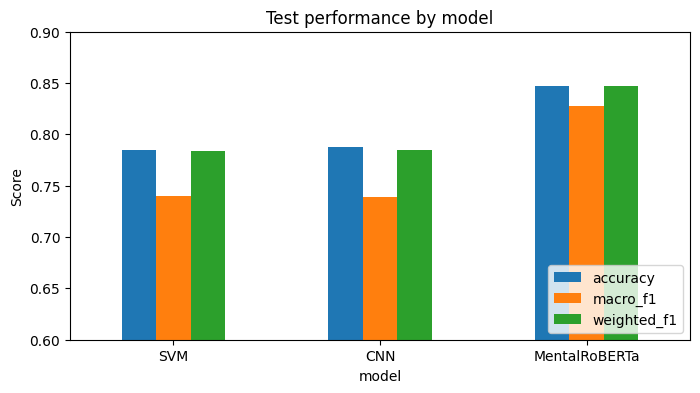

In [ ]:
metrics[["accuracy", "macro_f1", "weighted_f1"]].plot.bar(figsize=(8, 4), rot=0, ylim=(0.6, 0.9))
plt.title("Test performance by model")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.show()

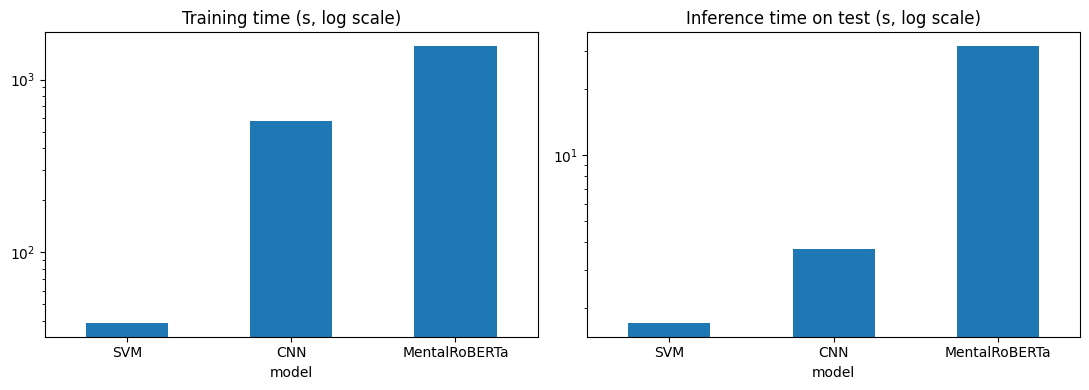

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metrics["train_time_s"].plot.bar(ax=axes[0], rot=0, logy=True, title="Training time (s, log scale)")
metrics["inference_time_s"].plot.bar(ax=axes[1], rot=0, logy=True, title="Inference time on test (s, log scale)")
plt.tight_layout()
plt.show()

In [ ]:
test = pd.read_csv(f"{BASE_DIR}/test.csv")
preds = test[["id", "statement", "status"]].copy()
for name, f in MODELS.items():
    p = pd.read_csv(f"{BASE_DIR}/{f}_preds.csv")
    preds = preds.merge(p[["id", "pred"]].rename(columns={"pred": name}), on="id")

print(len(test), len(preds))
classes = sorted(preds["status"].unique())
y = preds["status"].values

7654 7654


,SVM,CNN,MentalRoBERTa,support
Anxiety,0.800,0.805,0.888,542
Bipolar,0.793,0.796,0.874,375
Depression,0.715,0.705,0.787,2261
Normal,0.926,0.931,0.961,2403
Personality disorder,0.633,0.593,0.735,134
Stress,0.606,0.620,0.786,344
Suicidal,0.708,0.721,0.764,1595


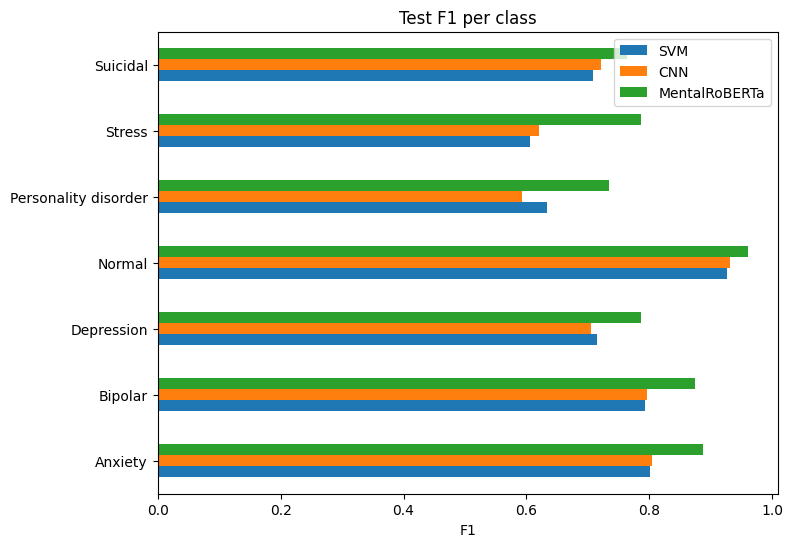

In [ ]:
per_class = pd.DataFrame({m: f1_score(y, preds[m], labels=classes, average=None) for m in MODELS},
                         index=classes)
per_class["support"] = preds["status"].value_counts().loc[classes]
display(per_class.round(3))

per_class[list(MODELS)].plot.barh(figsize=(8, 6))
plt.title("Test F1 per class")
plt.xlabel("F1")
plt.show()

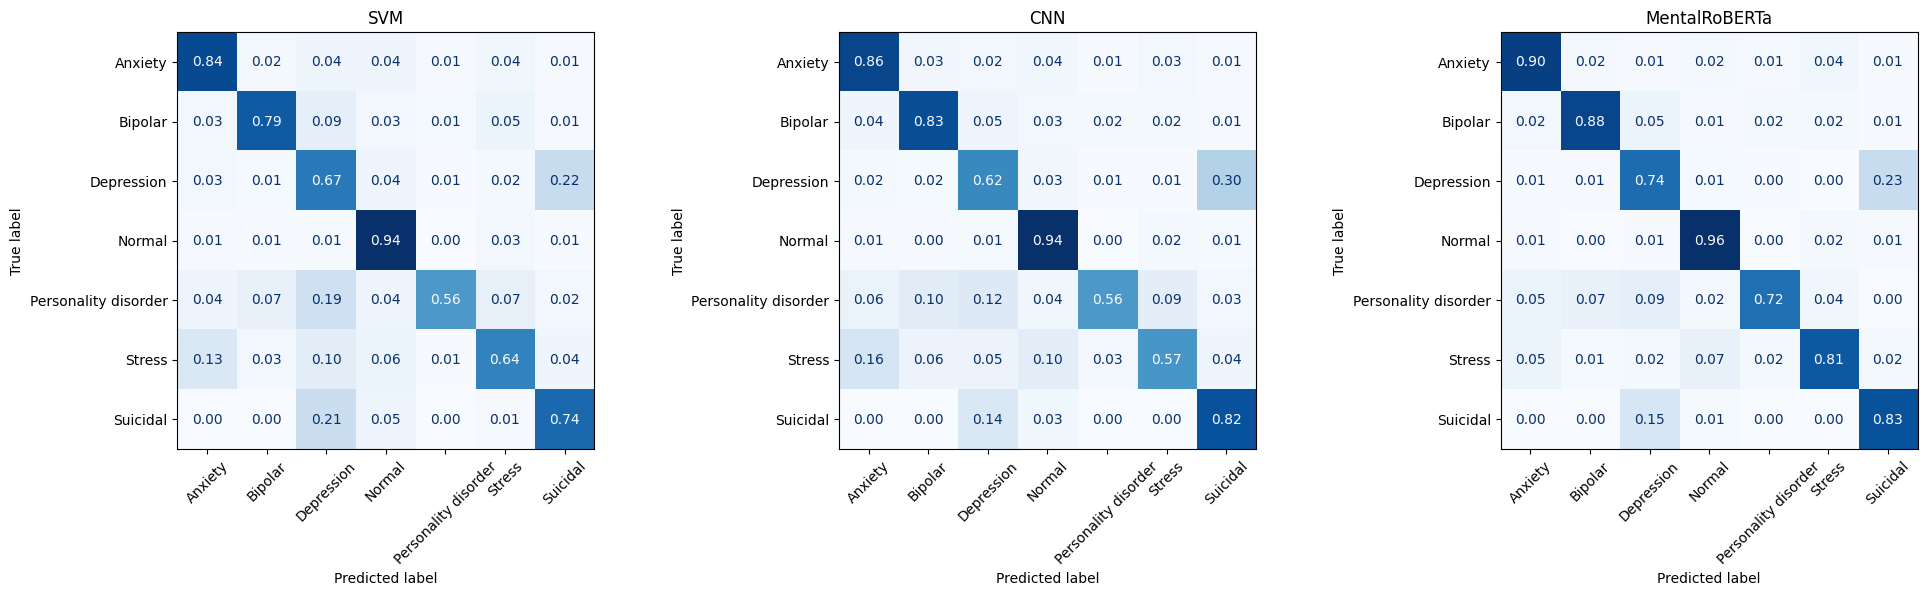

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, m in zip(axes, MODELS):
    ConfusionMatrixDisplay.from_predictions(y, preds[m], labels=classes, normalize="true",
                                            values_format=".2f", cmap="Blues", ax=ax,
                                            colorbar=False, xticks_rotation=45)
    ax.set_title(m)
plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(42)
boot = {m: [] for m in MODELS}
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))      # resample test posts with replacement
    for m in MODELS:
        boot[m].append(f1_score(y[idx], preds[m].values[idx], average="macro"))
boot = pd.DataFrame(boot)

ci = pd.DataFrame({
    "macro_f1": [f1_score(y, preds[m], average="macro") for m in MODELS],
    "ci_low": boot.quantile(0.025),
    "ci_high": boot.quantile(0.975),
}, index=list(MODELS))
display(ci.round(4))

for a, b in combinations(MODELS, 2):
    diff = boot[b] - boot[a]
    print(f"{b} - {a}: {diff.mean():+.4f}  95% CI [{diff.quantile(0.025):+.4f}, {diff.quantile(0.975):+.4f}]")

,macro_f1,ci_low,ci_high
SVM,0.7403,0.7231,0.7551
CNN,0.7387,0.7233,0.7537
MentalRoBERTa,0.8278,0.8148,0.8412


CNN - SVM: -0.0015  95% CI [-0.0154, +0.0127]
MentalRoBERTa - SVM: +0.0877  95% CI [+0.0724, +0.1035]
MentalRoBERTa - CNN: +0.0892  95% CI [+0.0743, +0.1043]


In [ ]:
rows = []
for a, b in combinations(MODELS, 2):
    a_right, b_right = preds[a] == y, preds[b] == y
    only_a = int((a_right & ~b_right).sum())
    only_b = int((~a_right & b_right).sum())
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue
    rows.append({"pair": f"{a} vs {b}", f"only first right": only_a,
                 f"only second right": only_b, "p_value": p})
pd.DataFrame(rows)

,pair,only first right,only second right,p_value
0,SVM vs CNN,488,510,5.062345e-01
1,SVM vs MentalRoBERTa,332,808,2.726820e-46
2,CNN vs MentalRoBERTa,323,777,1.057144e-43


In [ ]:
rows = []
for m in MODELS:
    dep, sui = preds["status"] == "Depression", preds["status"] == "Suicidal"
    rows.append({"model": m,
                 "Depression -> Suicidal": (preds.loc[dep, m] == "Suicidal").mean(),
                 "Suicidal -> Depression": (preds.loc[sui, m] == "Depression").mean()})
pd.DataFrame(rows).set_index("model").mul(100).round(1)   # % of each true class

,Depression -> Suicidal,Suicidal -> Depression
model,,
SVM,22.5,20.7
CNN,29.8,13.9
MentalRoBERTa,22.9,15.4


In [ ]:
correct = pd.DataFrame({m: preds[m] == y for m in MODELS})
overlap = {
    "all three right": correct.all(axis=1).sum(),
    "all three wrong": (~correct).all(axis=1).sum(),
    "only MentalRoBERTa right": (correct["MentalRoBERTa"] & ~correct["SVM"] & ~correct["CNN"]).sum(),
    "only MentalRoBERTa wrong": (~correct["MentalRoBERTa"] & correct["SVM"] & correct["CNN"]).sum(),
}
pd.Series(overlap, name="posts").to_frame().assign(percent=lambda d: (d["posts"] / len(y) * 100).round(1))

,posts,percent
all three right,5328,69.6
all three wrong,707,9.2
only MentalRoBERTa right,432,5.6
only MentalRoBERTa wrong,189,2.5


In [ ]:
pd.set_option("display.max_colwidth", 300)
all_wrong = preds[(~correct).all(axis=1)]
short = all_wrong[all_wrong["statement"].str.split().str.len().between(8, 60)]
short.sample(10, random_state=42)[["statement", "status"] + list(MODELS)]

,statement,status,SVM,CNN,MentalRoBERTa
1047,I am just overwhelmed. I cannot take this anymore. I have chest pain and headaches from all this.! I need to talk to someone ; (,Depression,Suicidal,Suicidal,Suicidal
130,"Been going through a rough patch, if anyone can chat atm. Can anyone talk right now?",Suicidal,Normal,Depression,Depression
5252,"I hate when I am trying to be social or myself ( I am usually shy) and someone says ""stop being weird"" it literally makes me shut down and go silent Life is so difficult",Suicidal,Depression,Depression,Depression
2446,"If I wanted to seek help, who do i look for? A psychologist o a psychiatrist? Whatever my insurance covers? If",Depression,Normal,Normal,Suicidal
4512,"Well, I never know when it is the best time to go, is it when I want to harm myself? Maybe when I just want to kill myself for real? I do not really know can someone tell me? :') When do I know I need to go to the mental hospital?",Depression,Suicidal,Suicidal,Suicidal
5178,Why do we cope with shame differently to others?[Shame-Coping Predictors]( How do you cope with shame?,Depression,Normal,Normal,Personality disorder
5733,been sat for minute listening to breathing apps and doing dare mediation it really exhausting,Depression,Normal,Normal,Normal
2943,"honestly, id really like to know. it sucks getting panic attacks even though you know you will be back next to your partner soon enough. how to cope with separation anxiety?",Suicidal,Normal,Anxiety,Depression
271,we are doing free personalised moon reading comment me if you re interested,Depression,Normal,Normal,Normal
7204,"I Have To Stay Alive Three people keep me alive: Mom, Dad, and my friend and landlord (until he makes it on Broadway.) One day the parents will die, and my landlord will have a big hit on Broadway, and I will no longer need my heart, lungs, brain, etc. Just won’t need it anymore.",Depression,Suicidal,Anxiety,Bipolar


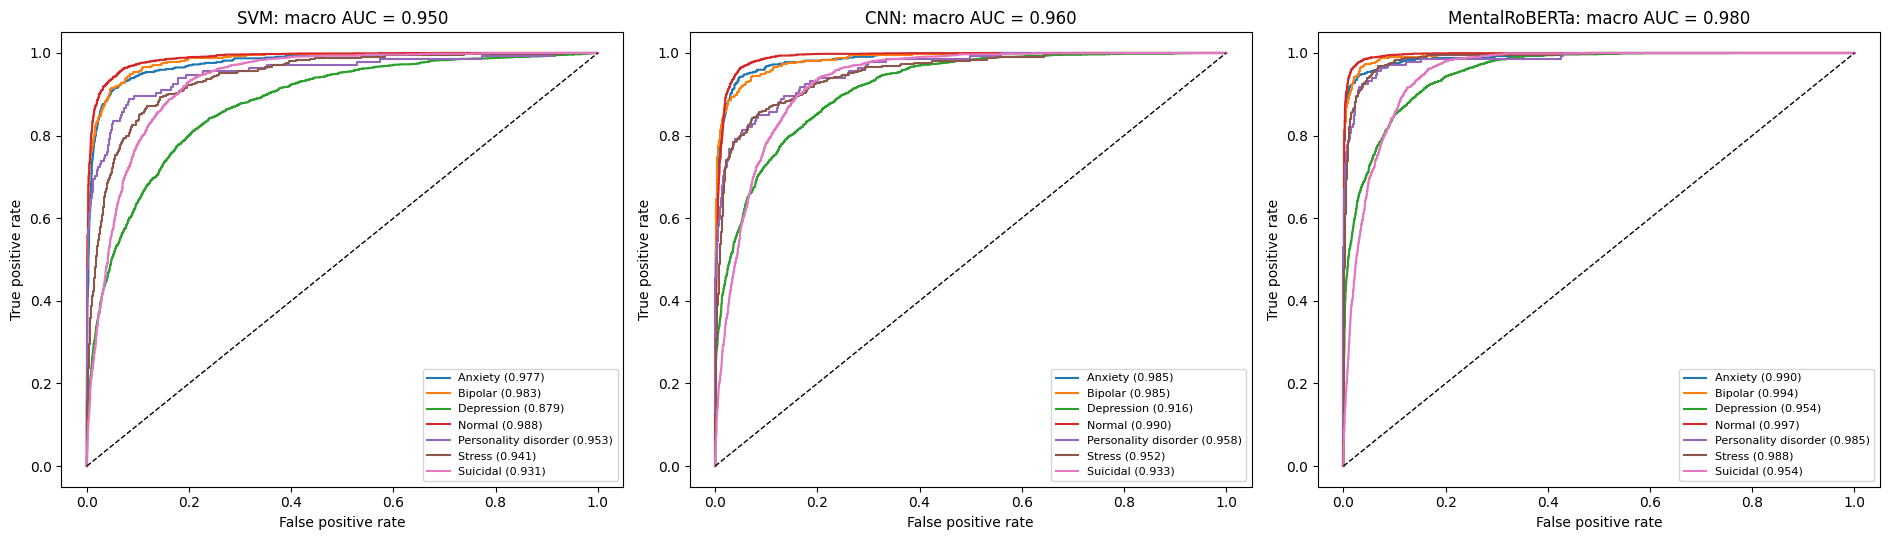

,SVM,CNN,MentalRoBERTa
Anxiety,0.977,0.985,0.990
Bipolar,0.983,0.985,0.994
Depression,0.879,0.916,0.954
Normal,0.988,0.990,0.997
Personality disorder,0.953,0.958,0.985
Stress,0.941,0.952,0.988
Suicidal,0.931,0.933,0.954
macro average,0.950,0.960,0.980


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

Y = label_binarize(y, classes=classes)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
auc_table = {}

for ax, (name, f) in zip(axes, MODELS.items()):
    s = pd.read_csv(f"{BASE_DIR}/{f}_scores.csv").set_index("id").loc[preds["id"], classes].values
    aucs = {}
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], s[:, k])
        aucs[c] = roc_auc_score(Y[:, k], s[:, k])
        ax.plot(fpr, tpr, label=f"{c} ({aucs[c]:.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"{name}: macro AUC = {np.mean(list(aucs.values())):.3f}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8, loc="lower right")
    auc_table[name] = aucs

plt.tight_layout()
plt.show()

auc_df = pd.DataFrame(auc_table)
auc_df.loc["macro average"] = auc_df.mean()
auc_df.round(3)